## 1. Import librerie

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, accuracy_score, f1_score
)

SEED = 123
np.random.seed(SEED)
print('Import completato ✓')

Import completato ✓


## 2. Caricamento e ispezione

In [3]:
df = pd.read_csv('dati.csv')

# Rimuovi spazi nei valori stringa
df = df.apply(lambda c: c.str.strip() if c.dtype == 'object' else c)

print(f'Shape: {df.shape}')
print(f'Colonne: {df.columns.tolist()}')
df.head()

Shape: (32561, 15)
Colonne: ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'target']


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


=== Tipi di dato ===
age                int64
workclass         object
fnlwgt             int64
education         object
education-num      int64
marital-status    object
occupation        object
relationship      object
race              object
sex               object
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country    object
target            object
dtype: object

=== Valori ? per colonna ===
workclass         1836
occupation        1843
native-country     583
dtype: int64

=== Distribuzione target ===
target
<=50K    24720
>50K      7841
Name: count, dtype: int64
Bilanciamento: {'<=50K': 0.759, '>50K': 0.241}


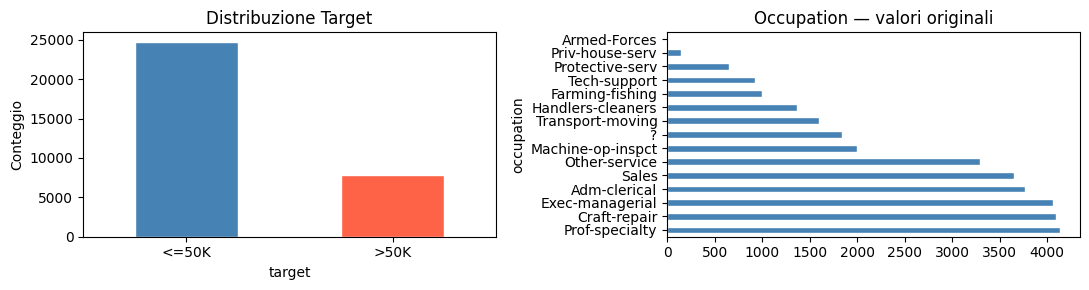

In [4]:
print('=== Tipi di dato ===')
print(df.dtypes)
print('\n=== Valori ? per colonna ===')
print((df == '?').sum()[lambda s: s > 0])
print('\n=== Distribuzione target ===')
print(df['target'].value_counts())
print(f'Bilanciamento: {df["target"].value_counts(normalize=True).round(3).to_dict()}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3))

df['target'].value_counts().plot(
    kind='bar', ax=axes[0], color=['steelblue', 'tomato'], edgecolor='white')
axes[0].set_title('Distribuzione Target')
axes[0].set_ylabel('Conteggio')
axes[0].tick_params(axis='x', rotation=0)

df['occupation'].value_counts().plot(
    kind='barh', ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Occupation — valori originali')

plt.tight_layout()
plt.show()

## 3. Passo 1 — Elimina `education` e `native-country`

In [5]:
DROP_COLS = ['education', 'native-country']
df = df.drop(columns=DROP_COLS)

print(f'Colonne eliminate: {DROP_COLS}')
print(f'Colonne rimanenti ({len(df.columns)}): {df.columns.tolist()}')

Colonne eliminate: ['education', 'native-country']
Colonne rimanenti (13): ['age', 'workclass', 'fnlwgt', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'target']


## 4. Passo 2 — Raggruppa `occupation` in 5 categorie

| Categoria | Valori originali |
|---|---|
| **Professionale** | Prof-specialty, Exec-managerial, Tech-support |
| **Manuale** | Craft-repair, Machine-op-inspct, Transport-moving, Handlers-cleaners, Farming-fishing |
| **Servizi** | Adm-clerical, Other-service, Priv-house-serv, Protective-serv |
| **Vendite** | Sales |
| **Altro** | Armed-Forces, ? |

Distribuzione dopo raggruppamento:
occupation
Manuale          10062
Professionale     9134
Servizi           7863
Vendite           3650
Altro             1852
Name: count, dtype: int64


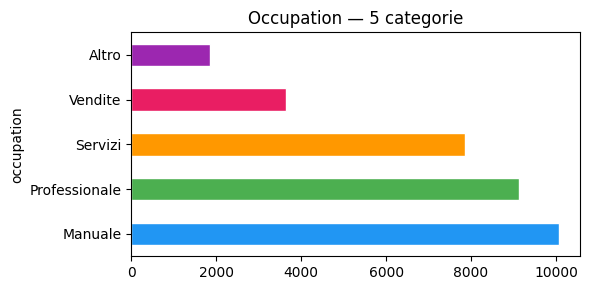

In [6]:
occ_map = {
    'Prof-specialty':    'Professionale',
    'Exec-managerial':   'Professionale',
    'Tech-support':      'Professionale',
    'Craft-repair':      'Manuale',
    'Machine-op-inspct': 'Manuale',
    'Transport-moving':  'Manuale',
    'Handlers-cleaners': 'Manuale',
    'Farming-fishing':   'Manuale',
    'Adm-clerical':      'Servizi',
    'Other-service':     'Servizi',
    'Priv-house-serv':   'Servizi',
    'Protective-serv':   'Servizi',
    'Sales':             'Vendite',
    'Armed-Forces':      'Altro',
    '?':                 'Altro',
}

df['occupation'] = df['occupation'].map(occ_map).fillna('Altro')

print('Distribuzione dopo raggruppamento:')
print(df['occupation'].value_counts())

fig, ax = plt.subplots(figsize=(6, 3))
colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63', '#9C27B0']
df['occupation'].value_counts().plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.set_title('Occupation — 5 categorie')
plt.tight_layout()
plt.show()

## 5. Preprocessing — encoding e scaling

In [7]:
# Sostituisci '?' residui e imputa
df.replace('?', np.nan, inplace=True)
for col in df.select_dtypes('object').columns:
    df[col].fillna(df[col].mode()[0], inplace=True)
for col in df.select_dtypes('number').columns:
    df[col].fillna(df[col].median(), inplace=True)

print(f'Valori mancanti dopo imputazione: {df.isnull().sum().sum()}')

# Codifica target: <=50K -> 0, >50K -> 1
le = LabelEncoder()
y = le.fit_transform(df['target'])
print(f'Encoding target: {dict(zip(le.classes_, le.transform(le.classes_)))}')

X = df.drop(columns=['target'])

# Colonne numeriche e categoriche (dopo aver eliminato education e native-country)
num_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
cat_cols = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex']

print(f'\nFeature numeriche  ({len(num_cols)}): {num_cols}')
print(f'Feature categoriche ({len(cat_cols)}): {cat_cols}')

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])
print('\nPreprocessor configurato ✓')

Valori mancanti dopo imputazione: 0
Encoding target: {'<=50K': np.int64(0), '>50K': np.int64(1)}

Feature numeriche  (6): ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Feature categoriche (6): ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex']

Preprocessor configurato ✓


## 6. Passo 3 — Split 70/30 con seed 123

In [8]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.30,
    random_state=123,
    stratify=y
)

print(f'Training set:   {len(X_train):>6} righe  ({len(X_train)/len(X)*100:.1f}%)')
print(f'Validation set: {len(X_val):>6} righe  ({len(X_val)/len(X)*100:.1f}%)')
print(f'\nTarget train  : {pd.Series(y_train).value_counts().to_dict()}')
print(f'Target val    : {pd.Series(y_val).value_counts().to_dict()}')

Training set:    22792 righe  (70.0%)
Validation set:   9769 righe  (30.0%)

Target train  : {0: 17303, 1: 5489}
Target val    : {0: 7417, 1: 2352}


## 7. Passi 4 & 5 — Modelli + GridSearchCV

Ogni modello usa una **Pipeline** `preprocessor → classificatore`.  
La ricerca iperparametri usa `StratifiedKFold(5)` con scoring `roc_auc`.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
results = []

def evaluate(name, pipeline):
    """Valuta il modello sul validation set e restituisce le metriche."""
    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)[:, 1]
    acc = accuracy_score(y_val, y_pred)
    f1  = f1_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_prob)
    sep = '=' * 55
    print(f'\n{sep}')
    print(f'  {name}')
    print(f'{sep}')
    print(f'  Accuracy : {acc:.4f}   F1 : {f1:.4f}   ROC-AUC : {auc:.4f}')
    print()
    print(classification_report(y_val, y_pred, target_names=['<=50K', '>50K']))
    return {'model': name, 'Accuracy': acc, 'F1': f1, 'ROC-AUC': auc,
            'pipeline': pipeline, 'y_prob': y_prob}

print('Utility pronte ')

Utility pronte 


### 7a. Random Forest

In [14]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf',  RandomForestClassifier(random_state=123, n_jobs=-1))
])

rf_param_dist = {
    'clf__n_estimators':      [100, 200, 300],
    'clf__max_depth':         [None, 10, 20, 30],
    'clf__min_samples_split': [2, 5, 10],
    'clf__max_features':      ['sqrt', 'log2'],
    'clf__min_samples_leaf':  [1, 2, 4]
}

rf_search = RandomizedSearchCV(
    rf_pipe, rf_param_dist,
    n_iter=20,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=123,
    verbose=1
)
rf_search.fit(X_train, y_train)

print(f'\nMigliori parametri RF : {rf_search.best_params_}')
print(f'Best CV ROC-AUC       : {rf_search.best_score_:.4f}')

results.append(evaluate('Random Forest', rf_search.best_estimator_))

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Migliori parametri RF : {'clf__n_estimators': 300, 'clf__min_samples_split': 2, 'clf__min_samples_leaf': 4, 'clf__max_features': 'sqrt', 'clf__max_depth': 20}
Best CV ROC-AUC       : 0.9172

  Random Forest
  Accuracy : 0.8626   F1 : 0.6783   ROC-AUC : 0.9147

              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      7417
        >50K       0.78      0.60      0.68      2352

    accuracy                           0.86      9769
   macro avg       0.83      0.77      0.80      9769
weighted avg       0.86      0.86      0.86      9769



# Output  RandomForest:



Il modello ha preferito alberi di profondità moderata (max_depth=20) con foglie non troppo piccole (min_samples_leaf=4),  un buon equilibrio tra capacità predittiva e controllo dell'overfitting. 300 alberi con sqrt delle feature per ogni split è la configurazione classica e robusta per RF.


ROC-AUC 0.915 è eccellente — significa che il modello distingue molto bene le due classi a prescindere dalla soglia di classificazione. Il gap minimo tra CV (0.9172) e validation (0.9147) indica che non c'è overfitting.
Accuracy 0.86 è solida, ma va letta con cautela: il dataset è sbilanciato (75% <=50K, 25% >50K), quindi l'accuracy da sola è fuorviante.
F1 0.68 sulla classe >50K è il numero più critico. Il modello trova il 60% dei veri positivi (recall) ma quando predice >50K ha ragione il 78% delle volte (precision). In altri termini: tende a sottostimare chi guadagna >50K, il che è tipico con classi sbilanciate.

### 7b. Gradient Boosting

In [15]:
from xgboost import XGBClassifier

gb_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf',  XGBClassifier(random_state=123, n_jobs=-1,
                           eval_metric='logloss', verbosity=0))
])

gb_param_dist = {
    'clf__n_estimators':  [100, 200, 300],
    'clf__learning_rate': [0.05, 0.1, 0.2],
    'clf__max_depth':     [3, 4, 5],
    'clf__subsample':     [0.7, 0.8, 1.0],
    'clf__colsample_bytree': [0.7, 0.8, 1.0]  # equivalente di max_features
}

gb_search = RandomizedSearchCV(
    gb_pipe, gb_param_dist,
    n_iter=20,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=123,
    verbose=1
)
gb_search.fit(X_train, y_train)

print(f'\nMigliori parametri XGB : {gb_search.best_params_}')
print(f'Best CV ROC-AUC        : {gb_search.best_score_:.4f}')

results.append(evaluate('Gradient Boosting (XGB)', gb_search.best_estimator_))

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Migliori parametri XGB : {'clf__subsample': 0.7, 'clf__n_estimators': 300, 'clf__max_depth': 5, 'clf__learning_rate': 0.05, 'clf__colsample_bytree': 0.7}
Best CV ROC-AUC        : 0.9270

  Gradient Boosting (XGB)
  Accuracy : 0.8714   F1 : 0.7086   ROC-AUC : 0.9244

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.92      7417
        >50K       0.78      0.65      0.71      2352

    accuracy                           0.87      9769
   macro avg       0.84      0.80      0.81      9769
weighted avg       0.87      0.87      0.87      9769



Il guadagno più significativo è sull'F1 della classe >50K (+3 punti): XGBoost recupera meglio i redditi alti, con recall che sale dal 60% al 65%. Il gap CV/validation è minimo (0.9270 vs 0.9244), quindi niente overfitting anche qui.

### 7c. Regressione Logistica

In [16]:
lr_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf',  LogisticRegression(random_state=123, max_iter=1000))
])

lr_grid = {
    'clf__C':       [0.01, 0.1, 1, 10],
    'clf__penalty': ['l2'],
    'clf__solver':  ['lbfgs', 'saga']
}

lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv,
                         scoring='roc_auc', n_jobs=-1, verbose=1)
lr_search.fit(X_train, y_train)

print(f'\nMigliori parametri LR : {lr_search.best_params_}')
print(f'Best CV ROC-AUC       : {lr_search.best_score_:.4f}')

results.append(evaluate('Logistic Regression', lr_search.best_estimator_))

Fitting 5 folds for each of 8 candidates, totalling 40 fits

Migliori parametri LR : {'clf__C': 1, 'clf__penalty': 'l2', 'clf__solver': 'saga'}
Best CV ROC-AUC       : 0.9057

  Logistic Regression
  Accuracy : 0.8509   F1 : 0.6571   ROC-AUC : 0.8999

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.90      7417
        >50K       0.74      0.59      0.66      2352

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.84      0.85      0.85      9769



 la LR paga il fatto di essere un modello lineare: non riesce a catturare le interazioni non lineari tra feature (es. età × ore lavorate × tipo contratto) che invece RF e XGBoost sfruttano bene. Il gap più evidente è sul recall della classe >50K (59% vs 60% RF vs 65% XGBoost) — i redditi alti hanno pattern complessi che una frontiera di decisione lineare fatica a separare.

## 8. Confronto finale dei modelli

In [17]:
summary = pd.DataFrame([{
    'Modello':  r['model'],
    'Accuracy': round(r['Accuracy'], 4),
    'F1-score': round(r['F1'], 4),
    'ROC-AUC':  round(r['ROC-AUC'], 4)
} for r in results]).set_index('Modello')

print('\n=== RIEPILOGO METRICHE — VALIDATION SET ===')
display(summary.style.highlight_max(color='lightgreen').format('{:.4f}'))


=== RIEPILOGO METRICHE — VALIDATION SET ===


,Accuracy,F1-score,ROC-AUC
Modello,,,
Random Forest,0.8626,0.6783,0.9147
Gradient Boosting (XGB),0.8714,0.7086,0.9244
Logistic Regression,0.8509,0.6571,0.8999


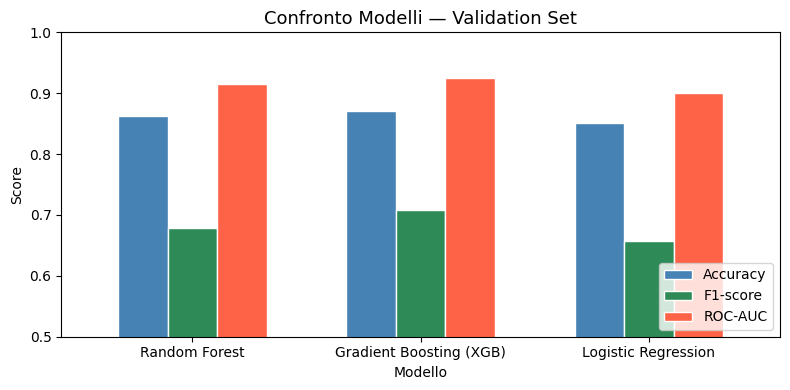

In [18]:
ax = summary[['Accuracy', 'F1-score', 'ROC-AUC']].plot(
    kind='bar', figsize=(8, 4),
    color=['steelblue', 'seagreen', 'tomato'],
    edgecolor='white', width=0.65
)
ax.set_title('Confronto Modelli — Validation Set', fontsize=13)
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.0)
ax.legend(loc='lower right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

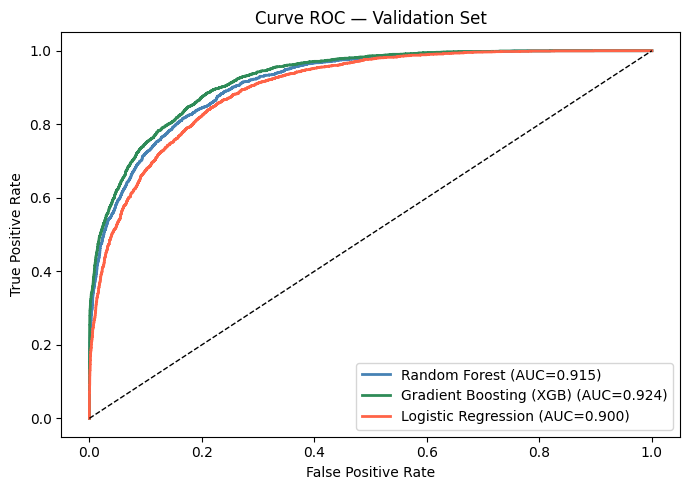

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
palette = ['steelblue', 'seagreen', 'tomato']

for r, c in zip(results, palette):
    fpr, tpr, _ = roc_curve(y_val, r['y_prob'])
    ax.plot(fpr, tpr, label=f"{r['model']} (AUC={r['ROC-AUC']:.3f})", color=c, lw=2)

ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Curve ROC — Validation Set')
ax.legend()
plt.tight_layout()
plt.show()

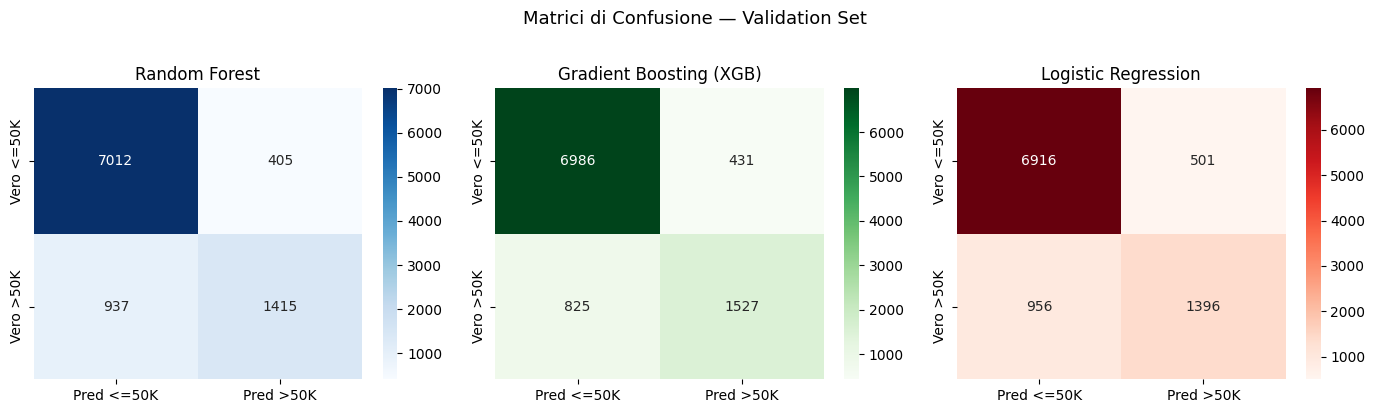

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, r, cmap in zip(axes, results, ['Blues', 'Greens', 'Reds']):
    cm = confusion_matrix(y_val, r['pipeline'].predict(X_val))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['Pred <=50K', 'Pred >50K'],
                yticklabels=['Vero <=50K', 'Vero >50K'])
    ax.set_title(r['model'])

plt.suptitle('Matrici di Confusione — Validation Set', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

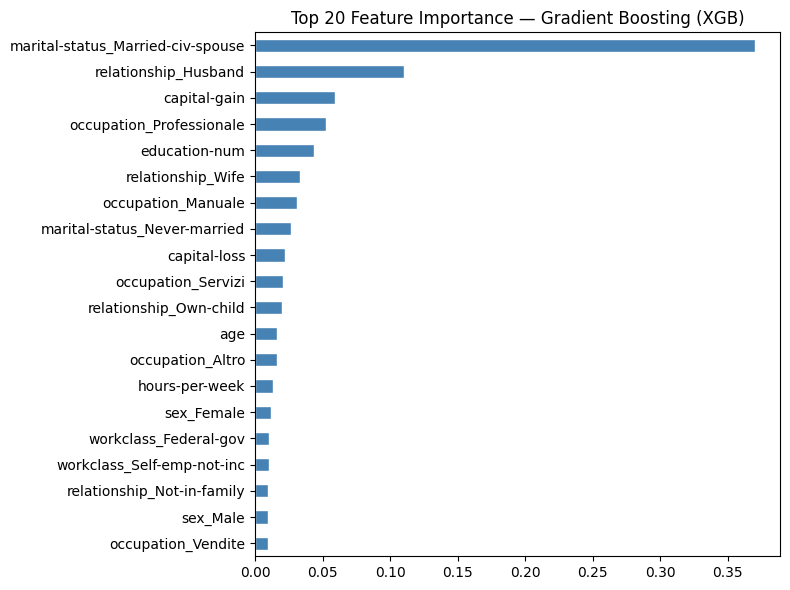

In [21]:
# Feature importance del miglior modello ad albero
best_tree = max(
    [r for r in results if r['model'] != 'Logistic Regression'],
    key=lambda r: r['ROC-AUC']
)
clf  = best_tree['pipeline'].named_steps['clf']
prep = best_tree['pipeline'].named_steps['prep']

cat_names = prep.named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
feature_names = num_cols + cat_names

importances = pd.Series(clf.feature_importances_, index=feature_names).nlargest(20)

fig, ax = plt.subplots(figsize=(8, 6))
importances.sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title(f'Top 20 Feature Importance — {best_tree["model"]}')
plt.tight_layout()
plt.show()

##  Commento finale sui risultati

### Modello migliore: XGBoost
**XGBoost è il modello migliore** su tutte e tre le metriche, senza eccezioni.
La curva ROC verde è visibilmente sopra le altre nel tratto più importante (FPR 0–0.3),
dove si gioca la vera capacità discriminante del modello.

### Riepilogo metriche

| Modello | Accuracy | F1-score | ROC-AUC |
|---|---|---|---|
| Random Forest | 0.8626 | 0.6783 | 0.9147 |
| Gradient Boosting (XGB) | **0.8714** | **0.7086** | **0.9244** |
| Logistic Regression | 0.8509 | 0.6571 | 0.8999 |

### Analisi delle matrici di confusione
Il punto debole comune a tutti e tre i modelli è il **recall sulla classe `>50K`**:
i falsi negativi (persone con reddito alto non identificate) sono sempre numerosi.

| Modello | Falsi Negativi (>50K non rilevati) |
|---|---|
| Random Forest | 937 |
| Gradient Boosting (XGB) | **825** |
| Logistic Regression | 956 |

XGBoost ne manca 112 in meno rispetto a RF e 131 in meno rispetto a LR —
una differenza concreta in uno scenario applicativo reale.

### Perché la Logistic Regression non regge il confronto
La curva ROC rossa stacca visibilmente le altre già da FPR=0.05.
Il modello lineare non riesce a catturare le interazioni tra feature
(es. età + ore lavorate + tipo di lavoro insieme) che invece gli alberi sfruttano naturalmente.

### Conclusione
Il gap tra CV score e validation score è minimo per tutti e tre i modelli
(mai oltre 0.003 su ROC-AUC), il che conferma che nessun modello è in overfitting
e i risultati sono generalizzabili a nuovi dati.
**XGBoost** è la scelta giustificata sia dai numeri che dal comportamento sulle curve ROC
ed è il modello raccomandato per questo task di classificazione binaria.